In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Loading the DATASET
data = pd.read_csv("telecom_churn.csv")

In [4]:
data.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [5]:
# Display the  rows and columns
print("Dataset shape:", data.shape)

# column names
print(data.columns)

#Columns and data types
data.info()

# Missing Value
print("Missing values:", data.isnull().sum().sum())

Dataset shape: (3333, 20)
Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 

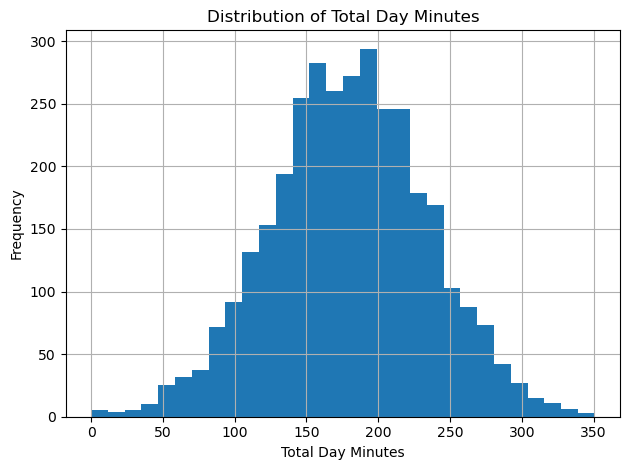

In [6]:
# Histogram Quantitative analysis
data["Total day minutes"].hist(bins=30)

plt.title("Distribution of Total Day Minutes")
plt.xlabel("Total Day Minutes")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

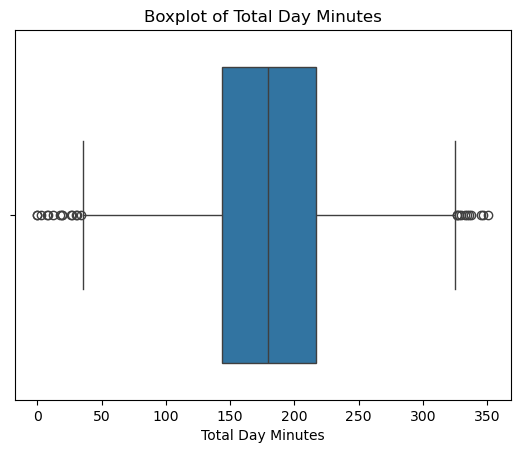

In [7]:
sns.boxplot(x=data["Total day minutes"])

plt.title("Boxplot of Total Day Minutes")
plt.xlabel("Total Day Minutes")
plt.show()

In [8]:
# Count customers by state
print(data["State"].value_counts().head())

# Count customers with each churn status
print(data["Churn"].value_counts())

# Count international plan categories
print(data["International plan"].value_counts())

# Count voicemail plan categories
print(data["Voice mail plan"].value_counts())

State
WV    106
MN     84
NY     83
AL     80
WI     78
Name: count, dtype: int64
Churn
False    2850
True      483
Name: count, dtype: int64
International plan
No     3010
Yes     323
Name: count, dtype: int64
Voice mail plan
No     2411
Yes     922
Name: count, dtype: int64


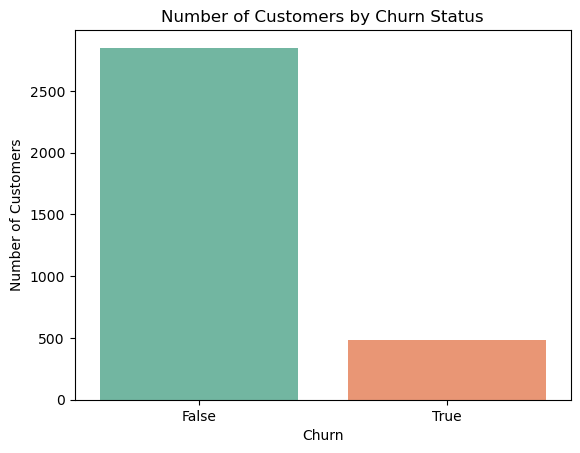

In [9]:
sns.countplot(
    data=data,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False )

plt.title("Number of Customers by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

['Total day charge', 'Total eve charge', 'Total night charge', 'Total intl charge']


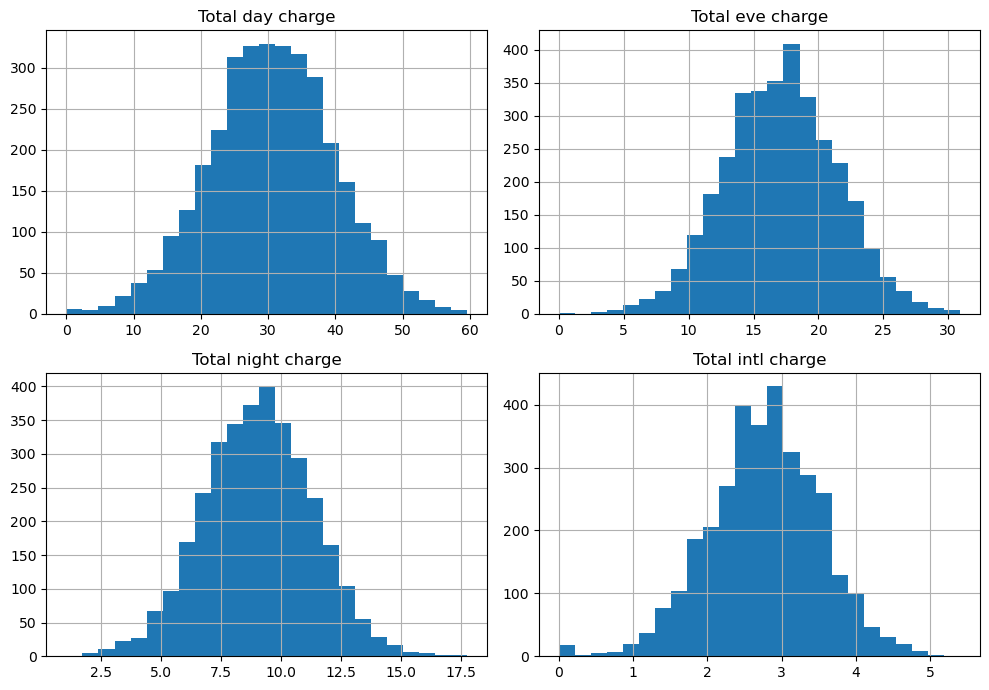

In [10]:
# Select columns containing charge measurements
features = [col for col in data.columns if "charge" in col]

print(features)

# Plot histograms for the selected features
data[features].hist(figsize=(10, 7), bins=25)
plt.tight_layout()
plt.show()

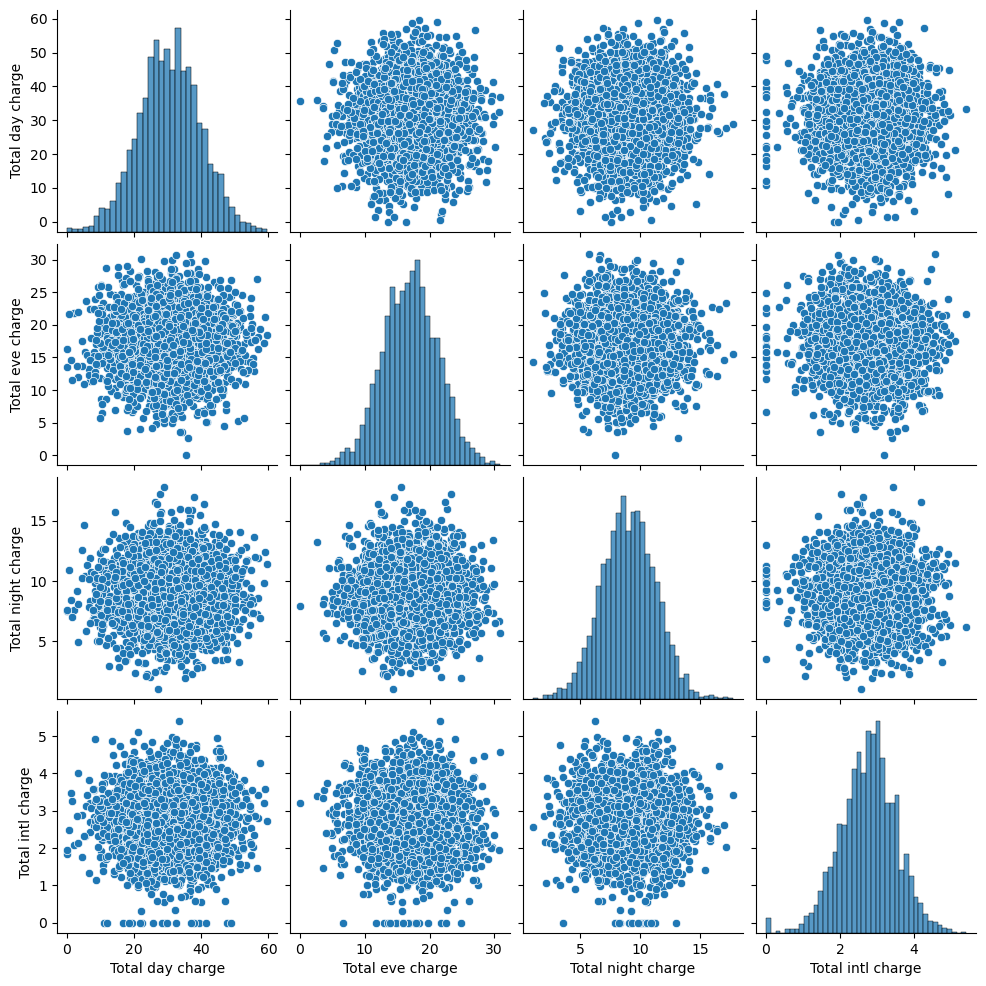

In [11]:
sns.pairplot(data[features])
plt.show()

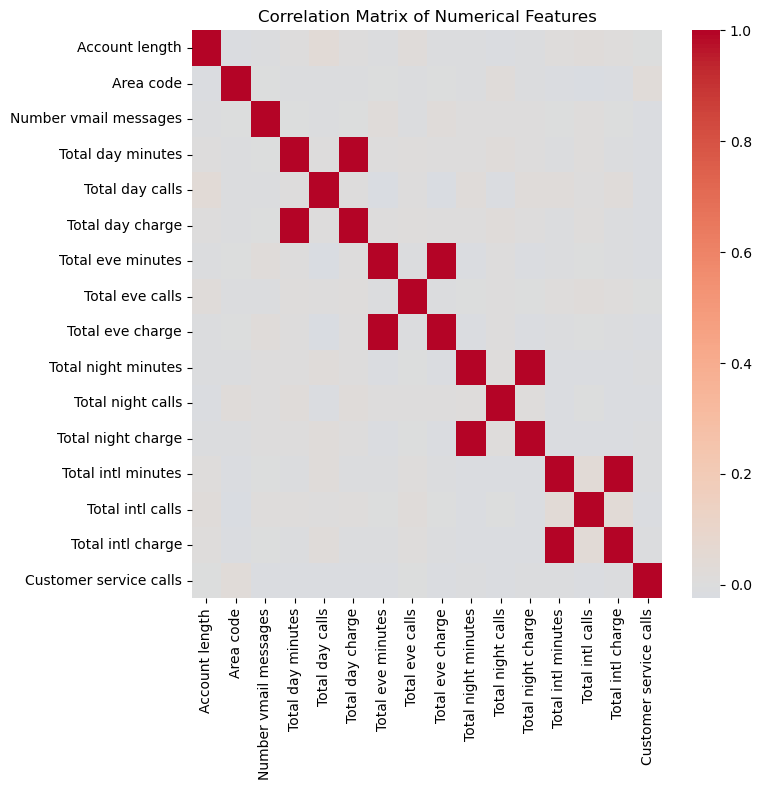

In [12]:
# Numerical columns
numeric_data = data.select_dtypes(include="number")

# Correlation of Matrix with Numeric data
correlation_matrix = numeric_data.corr()

# Display the heatmap
plt.figure(figsize=(8,8))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

First feature: Account length
Second feature: Number vmail messages


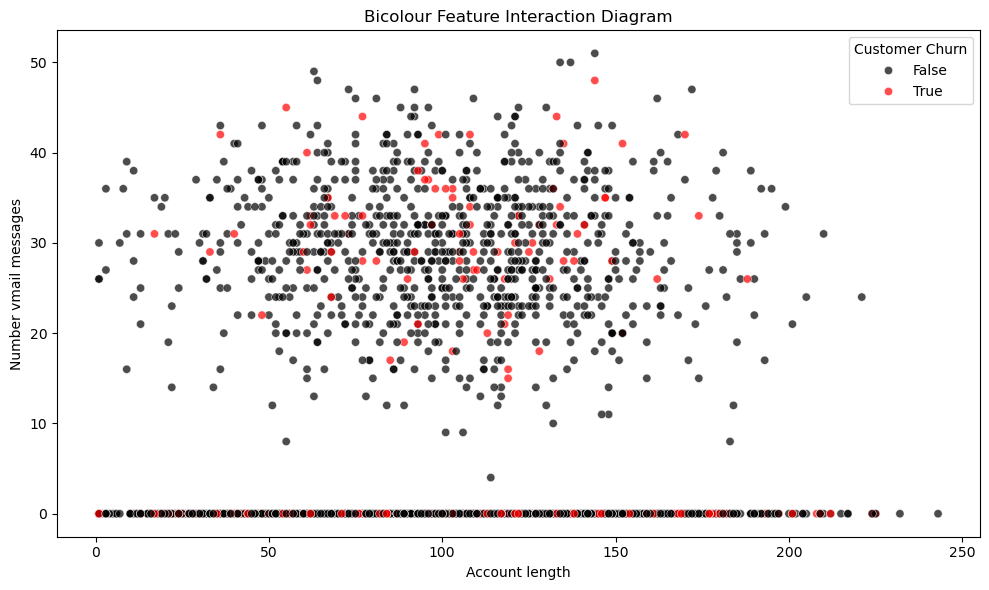

In [13]:
# Replace these with the last two digits of your SID

# MY SID : 2533551
last_digit = 1
second_last_digit = 5
# If the digits are identical, use the next column in order
if last_digit == second_last_digit:
    second_column = (last_digit + 1) % 10
else:
    second_column = second_last_digit
# Select the features using their column indices
x_column = data.columns[last_digit]
y_column = data.columns[second_column]

print("First feature:", x_column)
print("Second feature:", y_column)

# Draw the bicolour interaction diagram
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data,
    x=x_column,
    y=y_column,
    hue="Churn",
    palette={False: "Black", True: "red"},
    alpha=0.7 )

plt.title("Bicolour Feature Interaction Diagram")
plt.xlabel(x_column)
plt.ylabel(y_column)
plt.legend(title="Customer Churn")
plt.tight_layout()
plt.show()